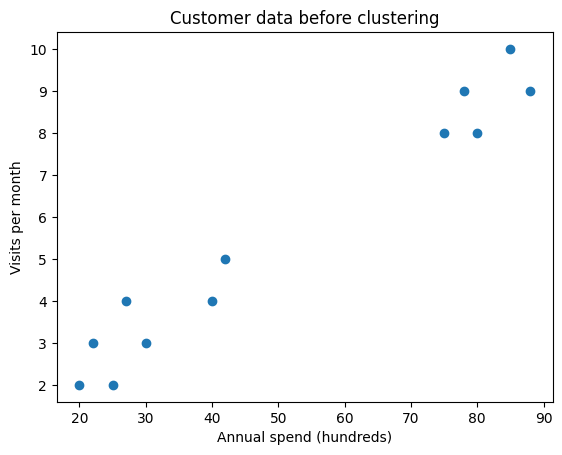

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

customers = pd.DataFrame({
    "AnnualSpend": [20,22,25,27,30,75,78,80,85,88,40,42],
    "VisitsPerMonth": [2,3,2,4,3,8,9,8,10,9,4,5]
})
plt.scatter(customers["AnnualSpend"],
            customers["VisitsPerMonth"])
plt.xlabel("Annual spend (hundreds)")
plt.ylabel("Visits per month")
plt.title("Customer data before clustering")
plt.show()

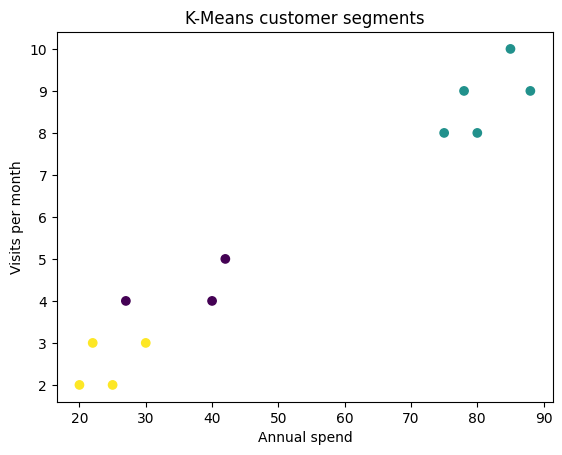

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

scaler = StandardScaler()
X_scaled = scaler.fit_transform(customers)

km = KMeans(n_clusters=3, random_state=42, n_init=10)
customers["Cluster"] = km.fit_predict(X_scaled)

plt.scatter(customers["AnnualSpend"],
            customers["VisitsPerMonth"],
            c=customers["Cluster"])
plt.xlabel("Annual spend")
plt.ylabel("Visits per month")
plt.title("K-Means customer segments")
plt.show()

In [3]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

for k in range(2, 6):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    print(k,
          "inertia:", round(model.inertia_, 2),
          "silhouette:", round(silhouette_score(X_scaled, labels), 3))

2 inertia: 2.03 silhouette: 0.786
3 inertia: 0.97 silhouette: 0.591
4 inertia: 0.66 silhouette: 0.449
5 inertia: 0.38 silhouette: 0.4


Cluster labels: [0 0 0 0 0 1 1 1 1 1 0 0]
Noise points: 0


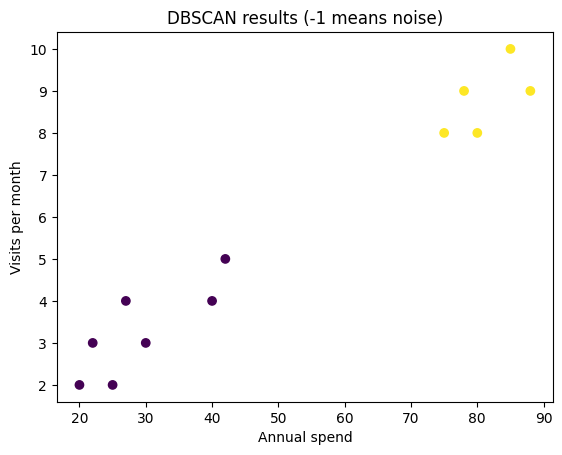

In [4]:
from sklearn.cluster import DBSCAN

db = DBSCAN(eps=0.8, min_samples=2)
db_labels = db.fit_predict(X_scaled)

print("Cluster labels:", db_labels)
print("Noise points:", sum(db_labels == -1))

plt.scatter(customers["AnnualSpend"],
            customers["VisitsPerMonth"],
            c=db_labels)
plt.xlabel("Annual spend")
plt.ylabel("Visits per month")
plt.title("DBSCAN results (-1 means noise)")
plt.show()

Explained variance: [0.73  0.229]


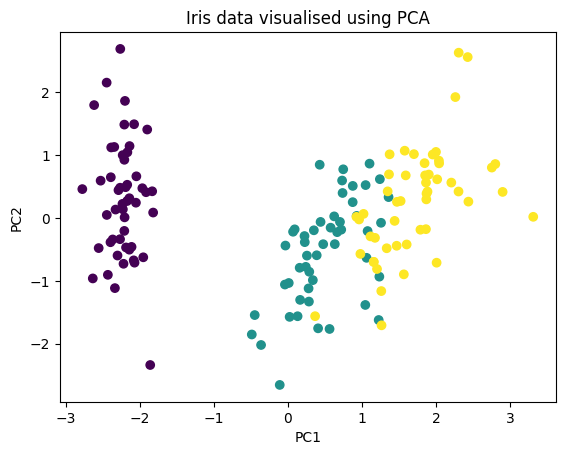

In [7]:
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

iris = load_iris()
X_iris = StandardScaler().fit_transform(iris.data)

pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_iris)

print("Explained variance:",
      pca.explained_variance_ratio_.round(3))
plt.scatter(X_2d[:,0], X_2d[:,1], c=iris.target)
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("Iris data visualised using PCA")
plt.show()

In [8]:
from sklearn.ensemble import IsolationForest
import numpy as np

transactions = np.array([
    [20, 2], [22, 3], [18, 2], [25, 3],
    [21, 2], [23, 4], [19, 3], [250, 20]
])

detector = IsolationForest(contamination=0.12, random_state=42)
labels = detector.fit_predict(transactions)

for row, label in zip(transactions, labels):
    print(row, "Anomaly" if label == -1 else "Normal")

[20  2] Normal
[22  3] Normal
[18  2] Normal
[25  3] Normal
[21  2] Normal
[23  4] Normal
[19  3] Normal
[250  20] Anomaly


Raw Customer Data:
    AnnualSpend  VisitsPerMonth
0            20               2
1            22               3
2            25               2
3            27               4
4            30               3
5            75               8
6            78               9
7            80               8
8            85              10
9            88               9
10           40               4
11           42               5


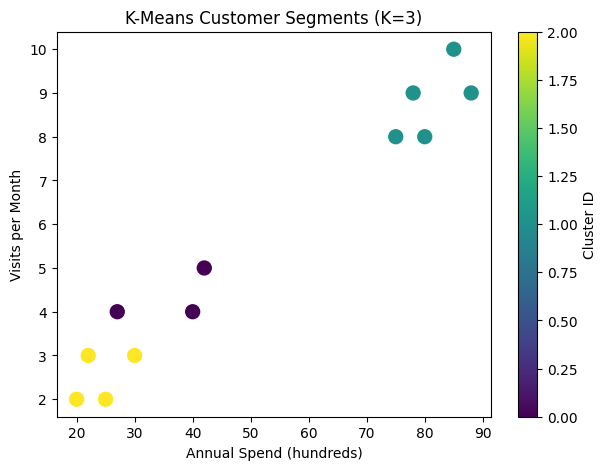


Cluster-wise Averages (K=3):
            AnnualSpend  VisitsPerMonth
Cluster_K3                             
0                 36.33            4.33
1                 81.20            8.80
2                 24.25            2.50

Model Evaluation Metrics (Elbow & Silhouette):
K=2 -> Inertia (Elbow): 2.03 | Silhouette Score: 0.786
K=3 -> Inertia (Elbow): 0.97 | Silhouette Score: 0.591
K=4 -> Inertia (Elbow): 0.66 | Silhouette Score: 0.449

DBSCAN Cluster Labels: [0 0 0 0 0 1 1 1 1 1 0 0]
Number of noise points (-1): 0


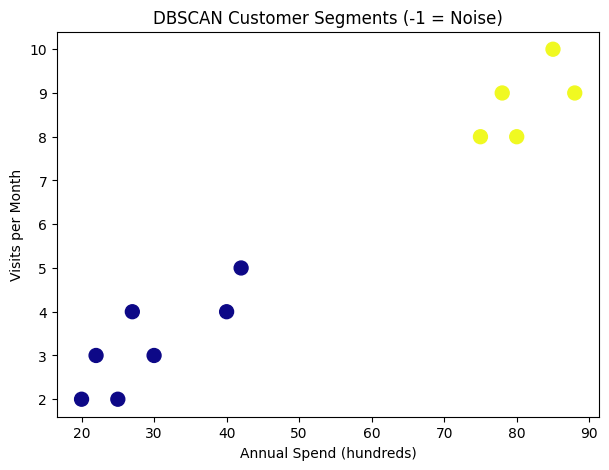

In [9]:
import os

os.environ["OMP_NUM_THREADS"] = "1"

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import DBSCAN, KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# 1. Create the customer dataset
customers = pd.DataFrame({
    "AnnualSpend": [20, 22, 25, 27, 30, 75, 78, 80, 85, 88, 40, 42],
    "VisitsPerMonth": [2, 3, 2, 4, 3, 8, 9, 8, 10, 9, 4, 5],
})

print("Raw Customer Data:")
print(customers)

# 2. Scale the two features and run K-Means with K=3
scaler = StandardScaler()
X_scaled = scaler.fit_transform(customers)

km3 = KMeans(n_clusters=3, random_state=42, n_init=10)
customers["Cluster_K3"] = km3.fit_predict(X_scaled)

# 3. Visualise the K=3 clusters and compute cluster-wise averages
plt.figure(figsize=(7, 5))
plt.scatter(
    customers["AnnualSpend"],
    customers["VisitsPerMonth"],
    c=customers["Cluster_K3"],
    cmap="viridis",
    s=100,
)
plt.xlabel("Annual Spend (hundreds)")
plt.ylabel("Visits per Month")
plt.title("K-Means Customer Segments (K=3)")
plt.colorbar(label="Cluster ID")
plt.show()

cluster_summary = (
    customers.groupby("Cluster_K3")[["AnnualSpend", "VisitsPerMonth"]]
    .mean()
    .round(2)
)
print("\nCluster-wise Averages (K=3):")
print(cluster_summary)

# 4. Try K=2, 3, and 4 and compare Elbow (inertia) and Silhouette scores
print("\nModel Evaluation Metrics (Elbow & Silhouette):")
for k in [2, 3, 4]:
  model = KMeans(n_clusters=k, random_state=42, n_init=10)
  labels = model.fit_predict(X_scaled)
  inertia = round(model.inertia_, 2)
  sil_score = round(silhouette_score(X_scaled, labels), 3)
  print(
      f"K={k} -> Inertia (Elbow): {inertia} | Silhouette Score: {sil_score}"
  )

# 5. Run DBSCAN and visualise results (-1 indicates noise)
db = DBSCAN(eps=0.8, min_samples=2)
customers["Cluster_DBSCAN"] = db.fit_predict(X_scaled)

print("\nDBSCAN Cluster Labels:", customers["Cluster_DBSCAN"].values)
print("Number of noise points (-1):", sum(customers["Cluster_DBSCAN"] == -1))

plt.figure(figsize=(7, 5))
plt.scatter(
    customers["AnnualSpend"],
    customers["VisitsPerMonth"],
    c=customers["Cluster_DBSCAN"],
    cmap="plasma",
    s=100,
)
plt.xlabel("Annual Spend (hundreds)")
plt.ylabel("Visits per Month")
plt.title("DBSCAN Customer Segments (-1 = Noise)")
plt.show()

Customer Data:
    Annual_Spending  Visits_Per_Month  Cluster
0              1200                 2        2
1              1500                 3        2
2              1800                 2        2
3              2000                 4        2
4              2200                 3        2
5              2500                 5        0
6              3000                 4        0
7              3200                 5        0
8              3500                 6        0
9              3800                 5        0
10             5000                 8        1
11             5200                 7        1
12             5500                 9        1
13             5800                 8        1
14             6000                10        1
15             6200                 9        1
16             6500                11        1
17             6800                10        1
18             7000                12        1
19             7200                11        

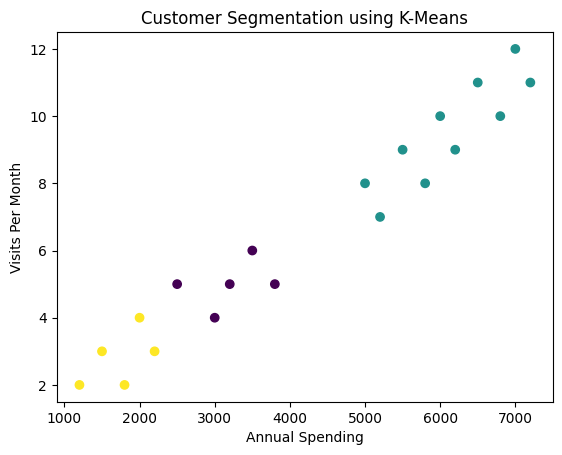


K Value | Silhouette Score
2      | 0.676
3      | 0.559
4      | 0.513


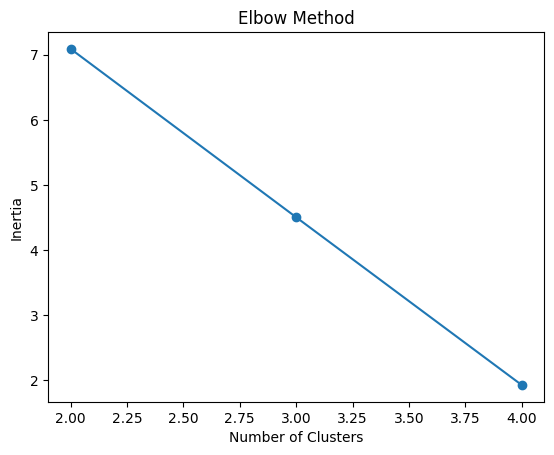

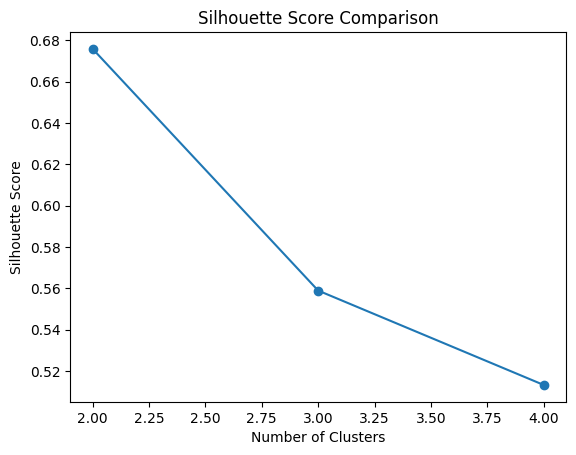


DBSCAN Results:
    Annual_Spending  Visits_Per_Month  Cluster  DBSCAN_Cluster
0              1200                 2        2               0
1              1500                 3        2               0
2              1800                 2        2               0
3              2000                 4        2               0
4              2200                 3        2               0
5              2500                 5        0               0
6              3000                 4        0               0
7              3200                 5        0               0
8              3500                 6        0               0
9              3800                 5        0               0
10             5000                 8        1               1
11             5200                 7        1               1
12             5500                 9        1               1
13             5800                 8        1               1
14             6000                10 

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score

data = {
    "Annual_Spending": [1200, 1500, 1800, 2000, 2200, 2500, 3000, 3200, 3500, 3800,
                        5000, 5200, 5500, 5800, 6000, 6200, 6500, 6800, 7000, 7200],
    "Visits_Per_Month": [2, 3, 2, 4, 3, 5, 4, 5, 6, 5,
                         8, 7, 9, 8, 10, 9, 11, 10, 12, 11]
}

df = pd.DataFrame(data)

X = df[["Annual_Spending", "Visits_Per_Month"]]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(X_scaled)

print("Customer Data:")
print(df)

print("\nAverage Spending of Each Cluster:")
print(df.groupby("Cluster")["Annual_Spending"].mean())

plt.scatter(
    df["Annual_Spending"],
    df["Visits_Per_Month"],
    c=df["Cluster"]
)
plt.xlabel("Annual Spending")
plt.ylabel("Visits Per Month")
plt.title("Customer Segmentation using K-Means")
plt.show()

k_values = [2, 3, 4]
inertia = []
silhouette = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    inertia.append(model.inertia_)
    silhouette.append(silhouette_score(X_scaled, labels))

print("\nK Value | Silhouette Score")
for k, score in zip(k_values, silhouette):
    print(k, "     |", round(score, 3))

plt.plot(k_values, inertia, marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

plt.plot(k_values, silhouette, marker="o")
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score Comparison")
plt.show()

dbscan = DBSCAN(eps=0.8, min_samples=2)
df["DBSCAN_Cluster"] = dbscan.fit_predict(X_scaled)

print("\nDBSCAN Results:")
print(df)

print("\nDBSCAN Cluster Counts:")
print(df["DBSCAN_Cluster"].value_counts())